# Train — ResNet-18

Trains and evaluates ResNet-18 using the tuned hyperparameters from `ARCH_HYPERPARAMS["resnet18"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: on
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']
Train: 947 | Val: 229 | Test: 567


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["resnet18"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders, same as every other architecture
# here -- its own (capped) batch size and image size, per cfg.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, tuned value = 24)


## Define the model (Transfer Learning with ResNet-18)

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with ResNet-18)
# ---------------------------------------------------------
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the tuned step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ResNet-18] Using gradient accumulation: 2 micro-batches per optimizer step (effective batch size ≈ micro_batch x 2).


[ResNet-18] Epoch   1/100 | LR: 8.42e-05 | train loss 0.9033 acc 0.626 | val loss 0.8335 acc 0.633 *


[ResNet-18] Epoch   2/100 | LR: 8.42e-05 | train loss 0.7689 acc 0.678 | val loss 0.9038 acc 0.590


[ResNet-18] Epoch   3/100 | LR: 8.42e-05 | train loss 0.7124 acc 0.728 | val loss 0.7537 acc 0.664 *


[ResNet-18] Epoch   4/100 | LR: 8.42e-05 | train loss 0.6327 acc 0.759 | val loss 0.6312 acc 0.716 *


...

[ResNet-18] Epoch  48/100 | LR: 8.42e-07 | train loss 0.1472 acc 0.951 | val loss 0.5460 acc 0.803


[ResNet-18] Epoch  49/100 | LR: 8.42e-07 | train loss 0.1361 acc 0.949 | val loss 0.5359 acc 0.808


[ResNet-18] Epoch  50/100 | LR: 8.42e-07 | train loss 0.1274 acc 0.964 | val loss 0.5335 acc 0.834


[ResNet-18] Epoch  51/100 | LR: 8.42e-08 | train loss 0.1353 acc 0.962 | val loss 0.5327 acc 0.825


[ResNet-18] Epoch  52/100 | LR: 8.42e-08 | train loss 0.1319 acc 0.955 | val loss 0.5267 acc 0.795

[ResNet-18] No val loss improvement for 10 epochs — stopping early at epoch 52.

[ResNet-18] Restored best checkpoint (val loss = 0.5092)


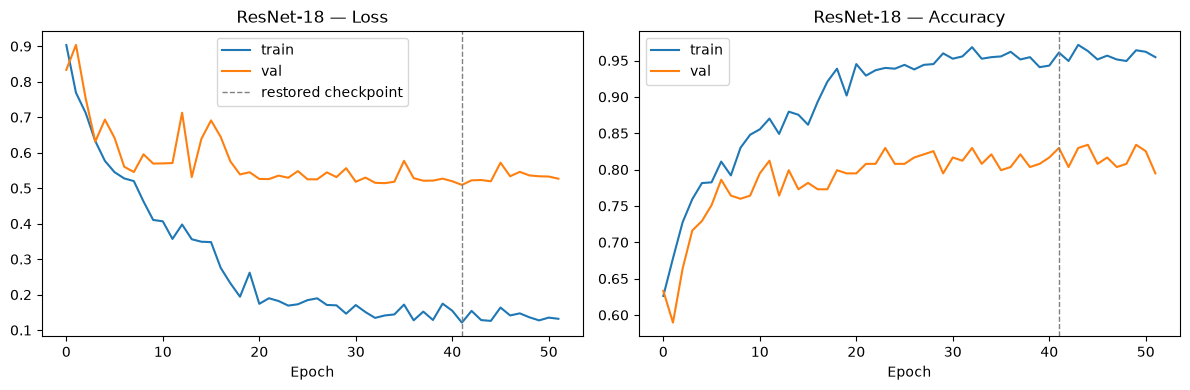

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18")

## Evaluate on the test set

[ResNet-18] Test accuracy: 0.806


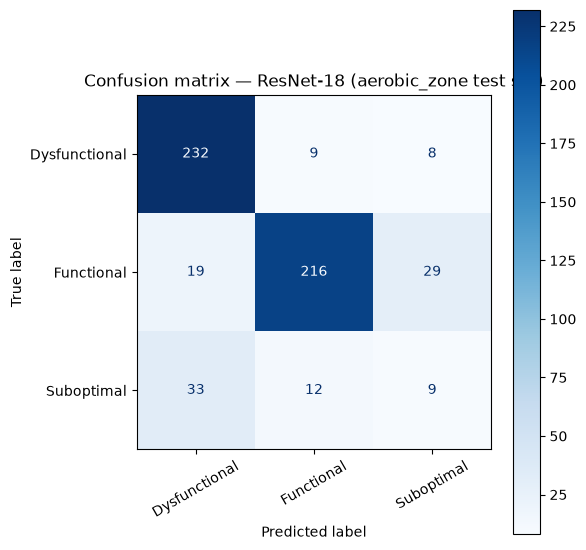

               precision    recall  f1-score   support

Dysfunctional      0.817     0.932     0.871       249
   Functional      0.911     0.818     0.862       264
   Suboptimal      0.196     0.167     0.180        54

     accuracy                          0.806       567
    macro avg      0.641     0.639     0.638       567
 weighted avg      0.802     0.806     0.801       567



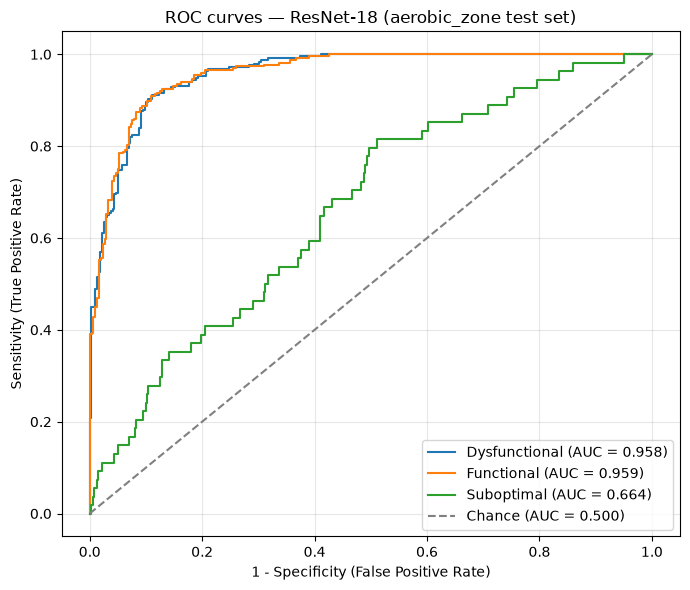

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.958
  Functional     : 0.959
  Suboptimal     : 0.664

Mean AUC (over 3/3 classes with test examples): 0.860


(np.float64(0.8059964726631393),
 {'Dysfunctional': 0.9576797757066,
  'Functional': 0.9588333833383339,
  'Suboptimal': 0.6643202656847881})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

This is the step the results notebook depends on — it pickles the metrics/history and saves the model state dict so nothing needs to be kept in memory or re-trained.

In [6]:
save_result("ResNet-18", "resnet18")

Saved results to ../results/aerobic_zone_aug/results_aerobic_zone_resnet18_chronological.pkl


Saved model weights to ../models/pad/aerobic_zone_resnet18_cnn.pt
